In [1]:
!pip install statsmodels

In [2]:
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.tsa.api as smt
import statsmodels as sm
import scipy.stats as scs
#Hay que registrar el método de conversión para fechas
from pandas.plotting import register_matplotlib_converters
import matplotlib.pyplot as plt
register_matplotlib_converters()

In [3]:
datos = pd.read_csv('crypto_BTC.csv', index_col=['timestamp'],  parse_dates=['timestamp'])
display(datos.head(3),datos.tail(3))

,price_usd
timestamp,
2025-03-17 00:34:14,82953.8
2025-03-17 01:34:12,82466.8
2025-03-17 02:34:12,82421.1


,price_usd
timestamp,
2025-10-17 02:19:15,108056.0
2025-10-17 02:39:38,108082.0
2025-10-17 02:53:05,108111.0


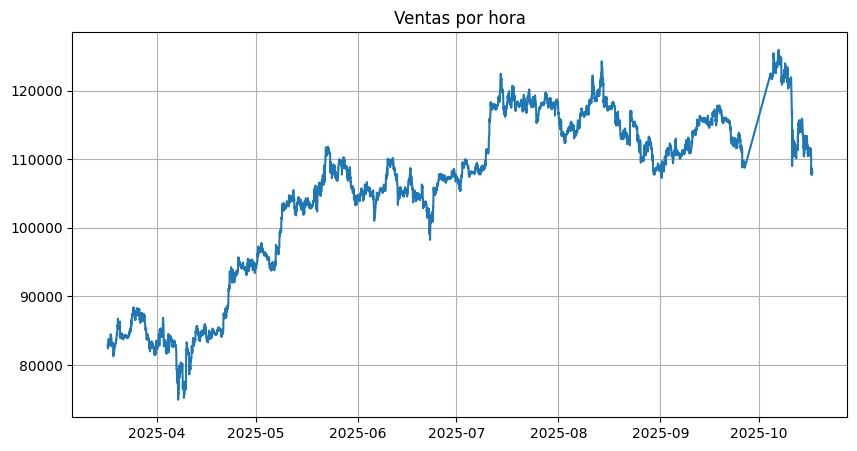

In [4]:
plt.figure(figsize=(10,5))
plt.plot(datos.price_usd)
plt.title('Ventas por hora')
plt.grid()
plt.show()

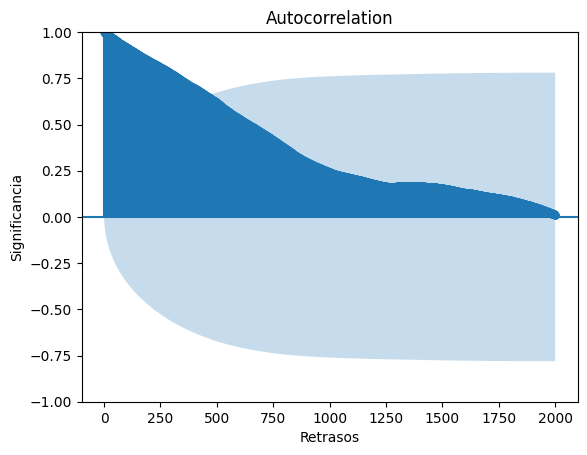

In [5]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(datos.price_usd,lags=range(1,2000))
plt.xlabel('Retrasos')
plt.ylabel('Significancia')
plt.show()

In [6]:
from sklearn.metrics import mean_absolute_error
import numpy as np
def mean_absolute_percentage_error(y_true,y_predict):
    return np.mean(np.abs((y_true-y_predict)/y_true)) * 100

In [7]:
def plot_moving_average(serie,window,figsize=(10,6), intervalos = False,escala = 2, anomalies = False):
    rolling_mean = serie.rolling(window=window).mean()
    plt.figure(figsize=figsize)
    plt.title("Media movil \n tamaño de ventana:{}".format(window))
    plt.plot(rolling_mean,'g',label='Tendencia por media movil')
    if intervalos:
        mae = mean_absolute_error(serie[window:],rolling_mean[window:])
        std = np.std(serie[window:] - rolling_mean[window:])
        low_ = rolling_mean - (mae+escala*std)
        upp_ = rolling_mean + (mae+escala*std)
        plt.plot(upp_,'r--', label="Límites sup/inf")
        plt.plot(low_,'r--')
        if anomalies:
            anoms = pd.DataFrame(index = serie.index,columns=serie.columns)
            anoms[serie<low_] = serie[serie<low_]
            anoms[serie>upp_] = serie[serie>upp_]
            plt.plot(anoms,'ro',markersize=10)   
    mape = mean_absolute_percentage_error(serie[window:], rolling_mean[window:])
    print('Error abs. medio porcentual: {:.3f}% '.format(mape))
    plt.plot(serie[window:],label='Valores reales')
    plt.legend(loc='upper left')
    plt.grid()
    plt.show()

/opt/conda/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:4109: FutureWarning: The behavior of DataFrame.std with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return std(axis=axis, dtype=dtype, out=out, ddof=ddof, **kwargs)


Error abs. medio porcentual: 1.518% 


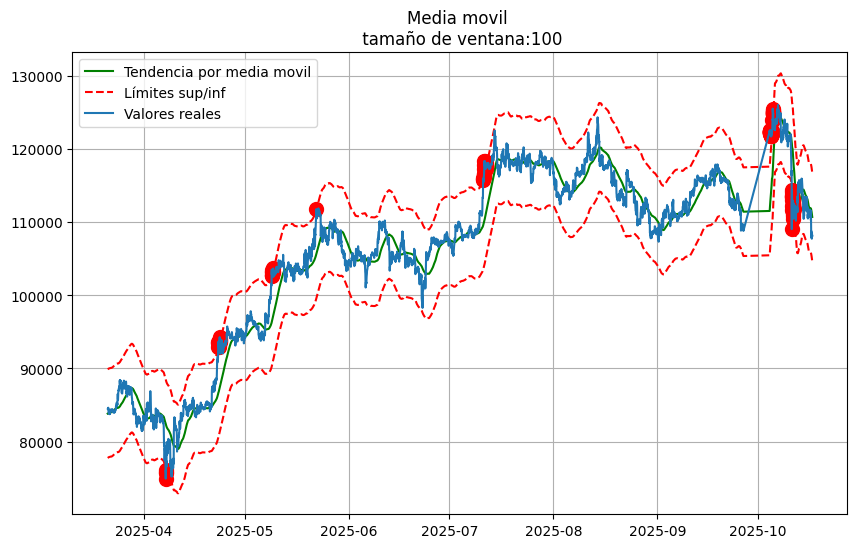

In [8]:
plot_moving_average(datos, window=100, intervalos=True, anomalies=True)

In [9]:
from statsmodels.tsa.api import ExponentialSmoothing

def plot_exp_smoothing(serie,periodo=None, test_size=0.2, predict=24,trend='add', seasonal='add'):

    d = serie.copy()
    d.index = pd.to_datetime(serie.index)

    # 2) Determinar frecuencia
    freq = d.index.inferred_freq
    if freq is None:
        serie = d.resample('h').mean().ffill()
        freq = 'h'
    d = d.asfreq(freq)
    
    n = len(serie)
    split = int(n * (1 - test_size))

    train = serie.iloc[:split]
    test  = serie.iloc[split:]

    ses = ExponentialSmoothing(train, trend='add',seasonal='add', seasonal_periods=periodo).fit()

    #pronostico
    ses_pred = ses.forecast(len(test)+predict)
    mape = mean_absolute_percentage_error(test,ses_pred[:-predict])
    print('Error abs. promedio {:.3f}% con periodo = {:d}'.format(mape,periodo))
    plt.figure(figsize=(10,4))
    plt.plot(train, label="Entrenamiento")
    plt.plot(test, label="Valores reales")
    plt.plot(ses_pred, label="Pronóstico")
    plt.title("Exponential Smoothing")
    plt.grid()
    plt.legend()
    plt.show()

Error abs. promedio 3.132% con periodo = 24


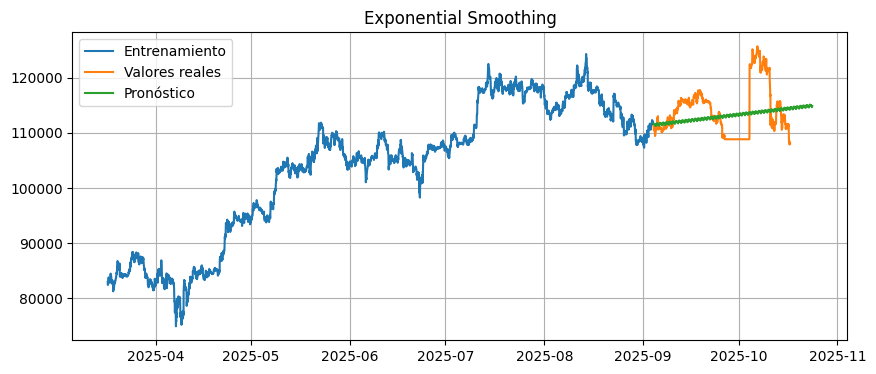

Error abs. promedio 3.220% con periodo = 168


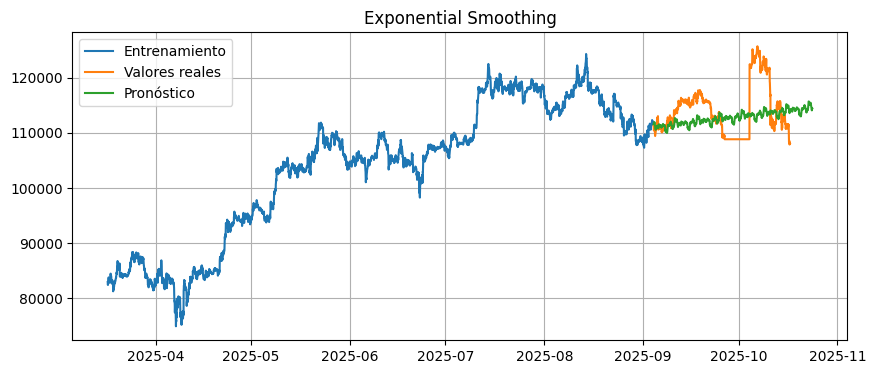

Error abs. promedio 3.205% con periodo = 240


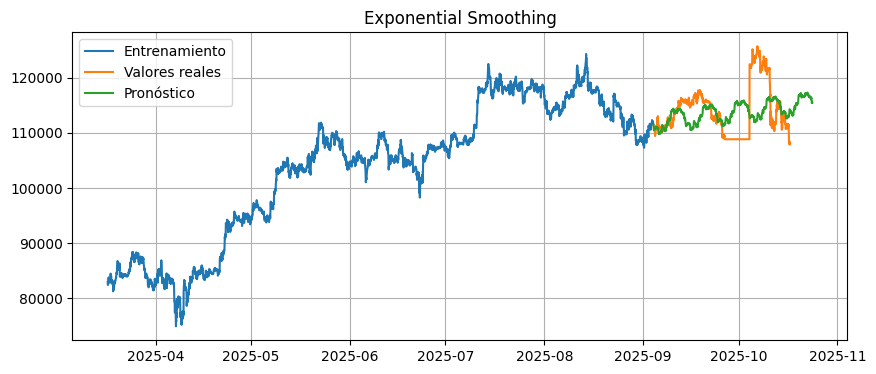

In [10]:
periodos = [24,168,240]
for p in periodos:
    plot_exp_smoothing(datos.price_usd,periodo= p,predict=168)

In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing as ES
from sklearn.metrics import mean_absolute_percentage_error

def plot_hw(serie, periodo=24, test_size=0.2, figsize=(10,5),predict=168):
    
    serie = serie.copy()
    serie.index = pd.to_datetime(serie.index)
    
    if serie.index.inferred_freq is None:
        serie = serie.resample('h').mean().ffill()
    serie = serie.asfreq('h')
        
    n = int(len(serie)*(1-test_size))
    train, test = serie[:n], serie[n:]    
    hw = ES(train, trend='add', seasonal='add', seasonal_periods=periodo).fit()
    future = hw.forecast(len(test)+predict)
    mape = mean_absolute_percentage_error(test, future[:-predict]) * 100
    print('Error abs. promedio {:.3f}% con periodo = {:d}'.format(mape,periodo))
    
    plt.figure(figsize=figsize)
    plt.title('Holt-Winters')
    plt.plot(train.index, train, label='Train')
    plt.plot(test.index, test, label='Test')
    plt.plot(future.index, future, label='Predicción')
    plt.legend()
    plt.grid()
    plt.show()


Error abs. promedio 3.132% con periodo = 24


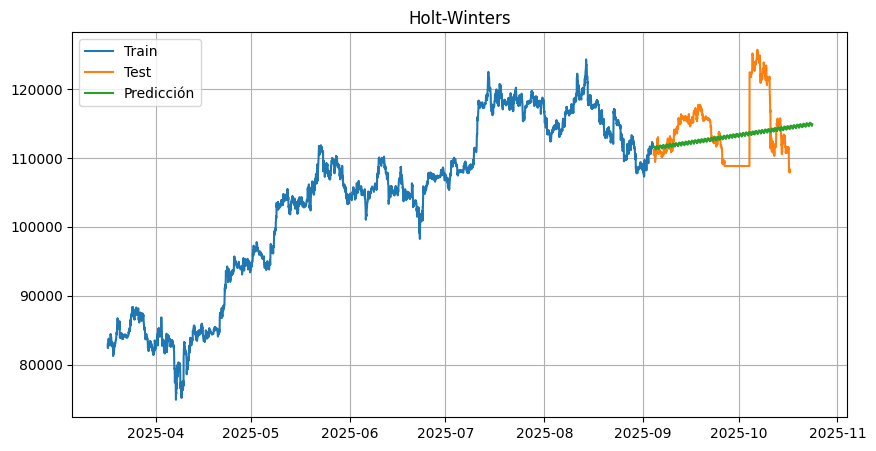

Error abs. promedio 3.220% con periodo = 168


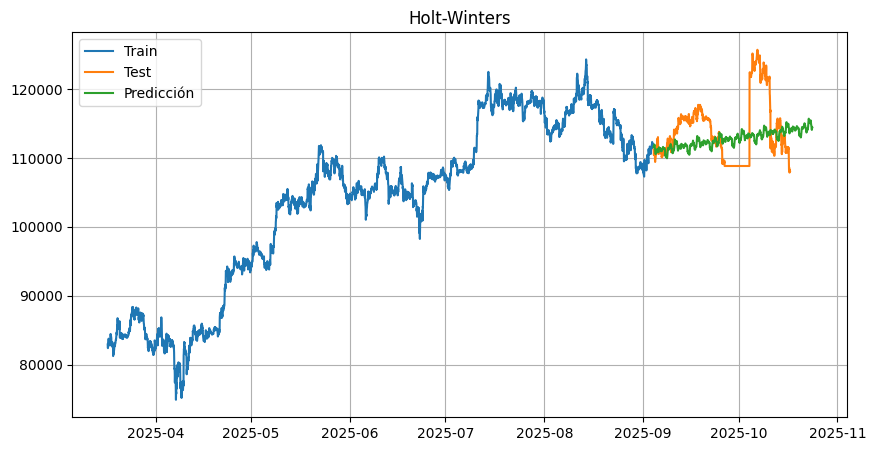

Error abs. promedio 3.205% con periodo = 240


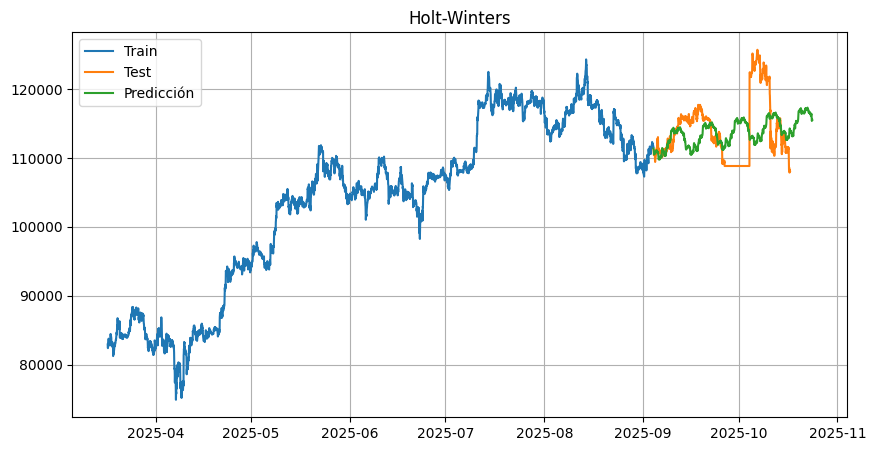

In [12]:
periodos = [24,168,240]
for p in periodos:
    plot_hw(datos.price_usd,periodo=p,predict =168)

## Regresión lineal

In [13]:
from sklearn.linear_model import LinearRegression

class TimeSeriesLinearRegressor:
    def __init__(self, lags=10, freq='h'):
        self.lags = lags
        self.freq = freq
        self.model = LinearRegression()
        self.fitted = False
        self.feature_names = [f"lag_{i}" for i in range(1, lags + 1)]

    def preparar_serie(self, serie):
        if not np.issubdtype(serie.index.dtype, np.datetime64):
             serie.index = pd.to_datetime(serie.index)
        serie = serie.sort_index()
        return serie.resample(self.freq).mean().ffill()

    def crear_lags(self, serie):
        lags_data = {'y': serie}
        for i in range(1, self.lags + 1):
            lags_data[f"lag_{i}"] = serie.shift(i)
        return pd.DataFrame(lags_data)
        
    def train_test_split(self, X, y, test_size=0.3):
        n = int(len(X) * (1 - test_size))
        return X.iloc[:n], X.iloc[n:], y.iloc[:n], y.iloc[n:]

    def fit(self, serie, test_size=0.3):
        self.serie_interna = self.preparar_serie(serie)
        data = self.crear_lags(self.serie_interna)
        
        y = data.dropna().y
        X = data.dropna().drop(['y'], axis=1)

        self.X_train, self.X_test, self.y_train, self.y_test = self.train_test_split(X, y, test_size)
        self.model.fit(self.X_train, self.y_train)
        self.fitted = True

    def predict_test(self):
        if not self.fitted: raise Exception("Modelo no entrenado")
        return pd.Series(self.model.predict(self.X_test), index=self.y_test.index)

    def score(self):
        if not self.fitted: raise Exception("Modelo no entrenado")
        y_pred = self.predict_test()
        mape = mean_absolute_percentage_error(self.y_test, y_pred)
        mae = mean_absolute_error(self.y_test, y_pred)
        return {"MAPE": mape, "MAE": mae}

    def forecast(self, steps):
        if not self.fitted: raise Exception("Primero entrena el modelo con .fit()")
        valores_recientes = list(self.serie_interna.iloc[-self.lags:].values)
        predicciones = []
        last_date = self.serie_interna.index[-1]
        future_dates = pd.date_range(start=last_date, periods=steps+1, freq=self.freq)[1:]

        for _ in range(steps):
            entrada = []
            for i in range(1, self.lags + 1):
                entrada.append(valores_recientes[-i])
            
            entrada_df = pd.DataFrame([entrada], columns=self.feature_names)
            pred = self.model.predict(entrada_df)[0]
            predicciones.append(pred)
            valores_recientes.append(pred) 
        return pd.Series(predicciones, index=future_dates)
    
    # --- AQUÍ ESTÁ LA MAGIA VISUAL ---
    def plot_all(self, steps=0, figsize=(20,10), std_scale=2):
        if not self.fitted: raise Exception("Modelo no entrenado")

        plt.figure(figsize=figsize)
        plt.plot(self.serie_interna.index, self.serie_interna, label="Datos Reales", color='black', linewidth=1, alpha=0.5)
        y_pred = self.predict_test()
        plt.plot(y_pred.index, y_pred, label="Validación (Modelo)", color='#1f77b4') # Azul

        residuals = self.y_test - y_pred
        std_error = residuals.std()
        
        upper_bound = y_pred + (std_error * std_scale)
        lower_bound = y_pred - (std_error * std_scale)
        
        plt.fill_between(y_pred.index, lower_bound, upper_bound, color='gray', alpha=0.2, label=f'Intervalo Confianza ({std_scale}$\sigma$)')

        anomalies = self.y_test[(self.y_test > upper_bound) | (self.y_test < lower_bound)]
        if not anomalies.empty:
            plt.scatter(anomalies.index, anomalies, color='red', zorder=10, s=30, label='Anomalías Detectadas')

        # 3. Forecast Futuro (Si aplica)
        if steps > 0:
            forecast_series = self.forecast(steps)
            plt.plot(forecast_series.index, forecast_series, label=f"Forecast ({steps} pasos)", color='green', linewidth=2)
            
            # Proyectamos la misma incertidumbre al futuro (Intervalo visual)
            f_upper = forecast_series + (std_error * std_scale)
            f_lower = forecast_series - (std_error * std_scale)
            plt.fill_between(forecast_series.index, f_lower, f_upper, color='green', alpha=0.1)

        plt.title(f"Regresión Autoregresiva lags =({self.lags})| Detectadas {len(anomalies)} anomalías")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

{'MAPE': 0.002113659318300431, 'MAE': 242.02382535640714}


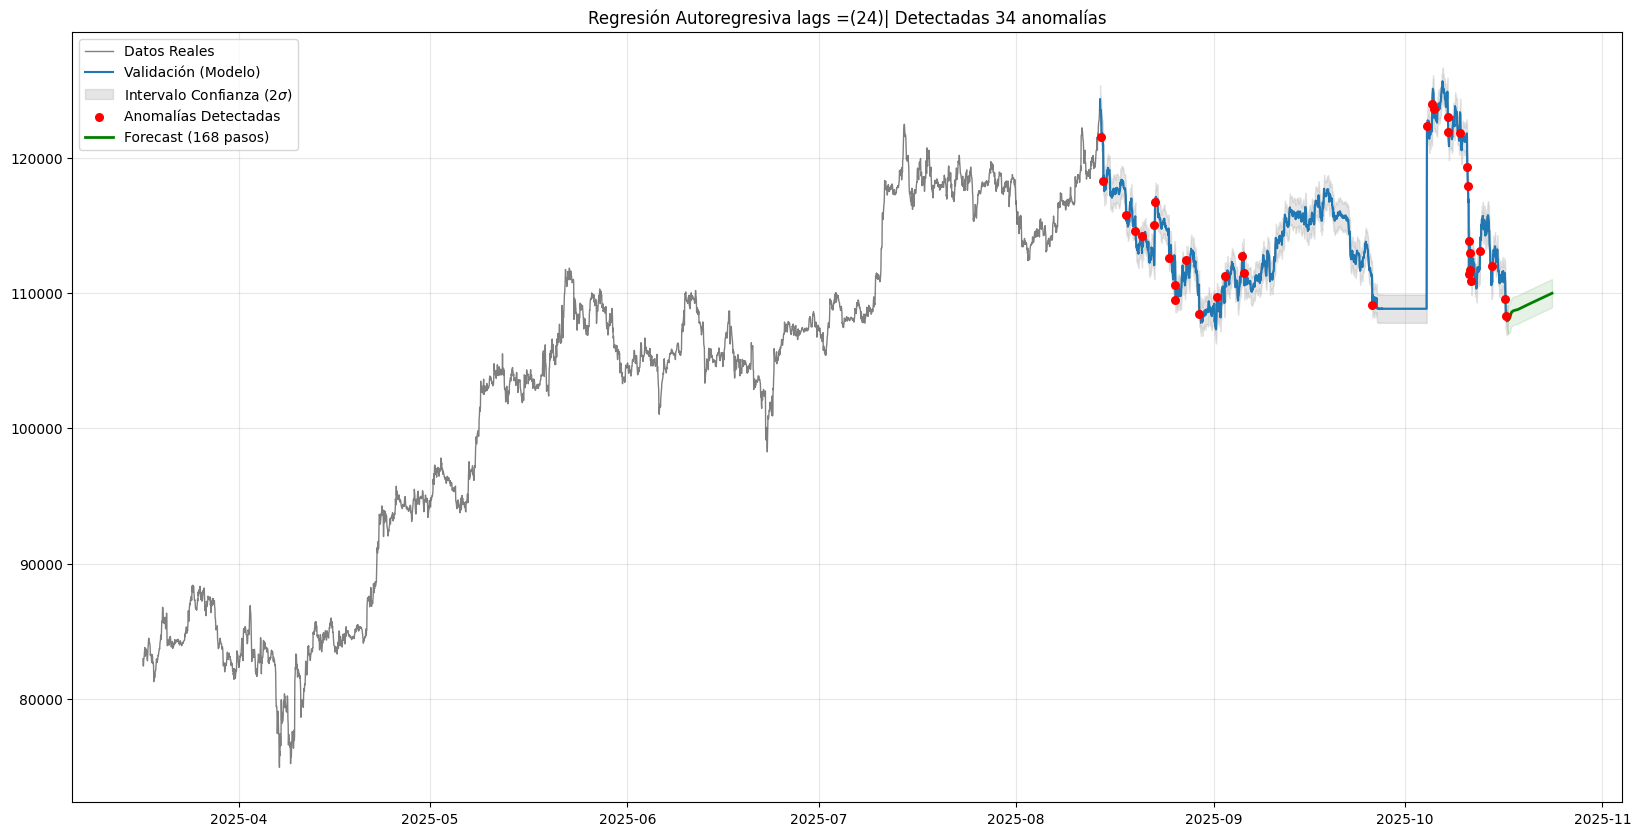

{'MAPE': 0.002238667970726429, 'MAE': 256.07959621836477}


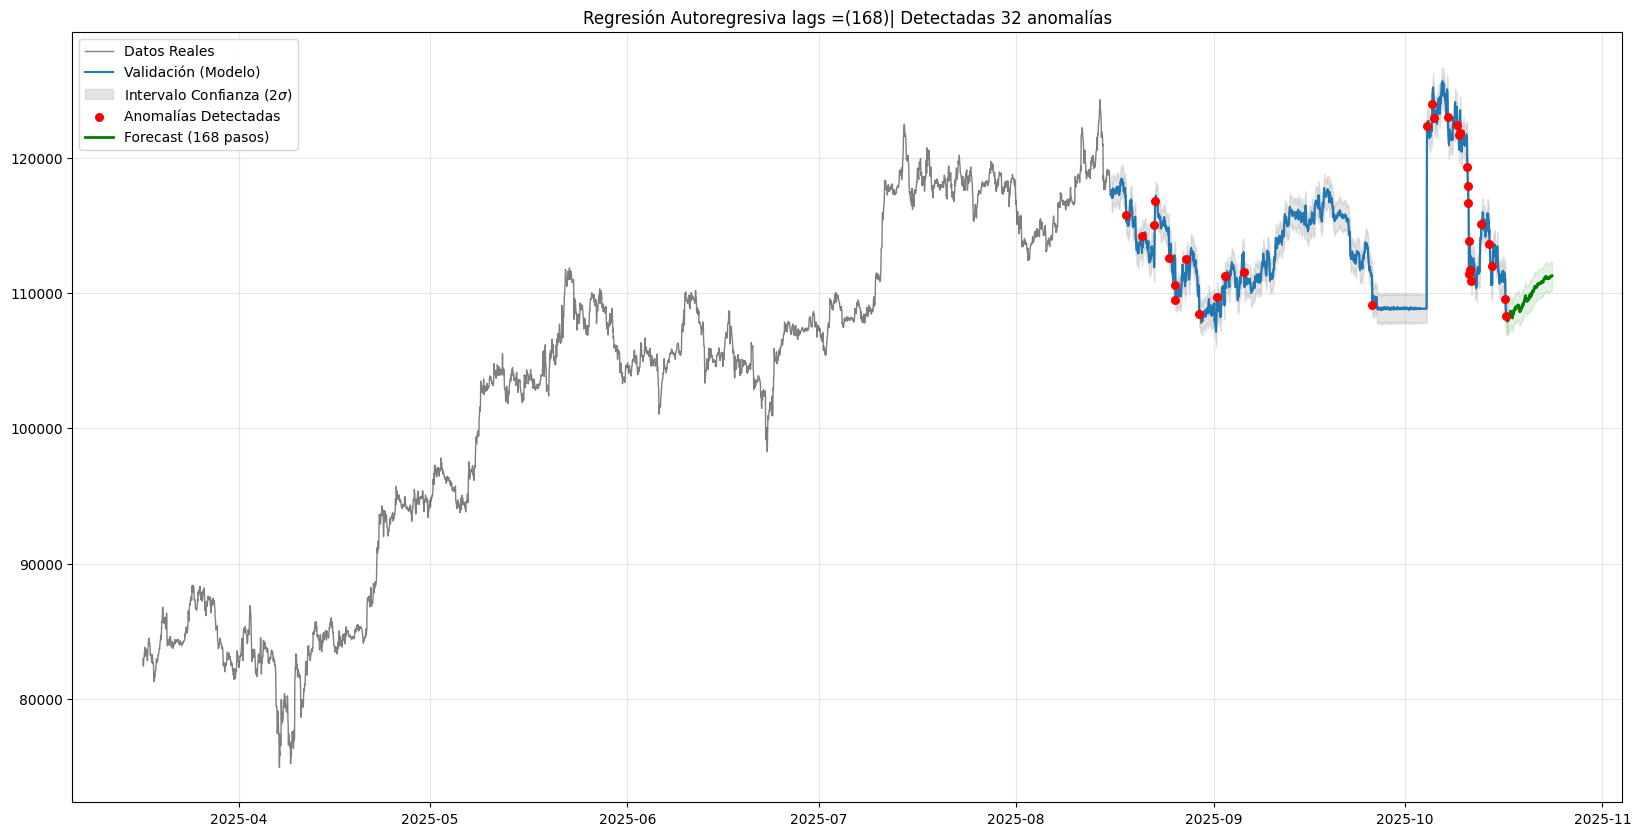

{'MAPE': 0.0023334616428419444, 'MAE': 266.70304540237055}


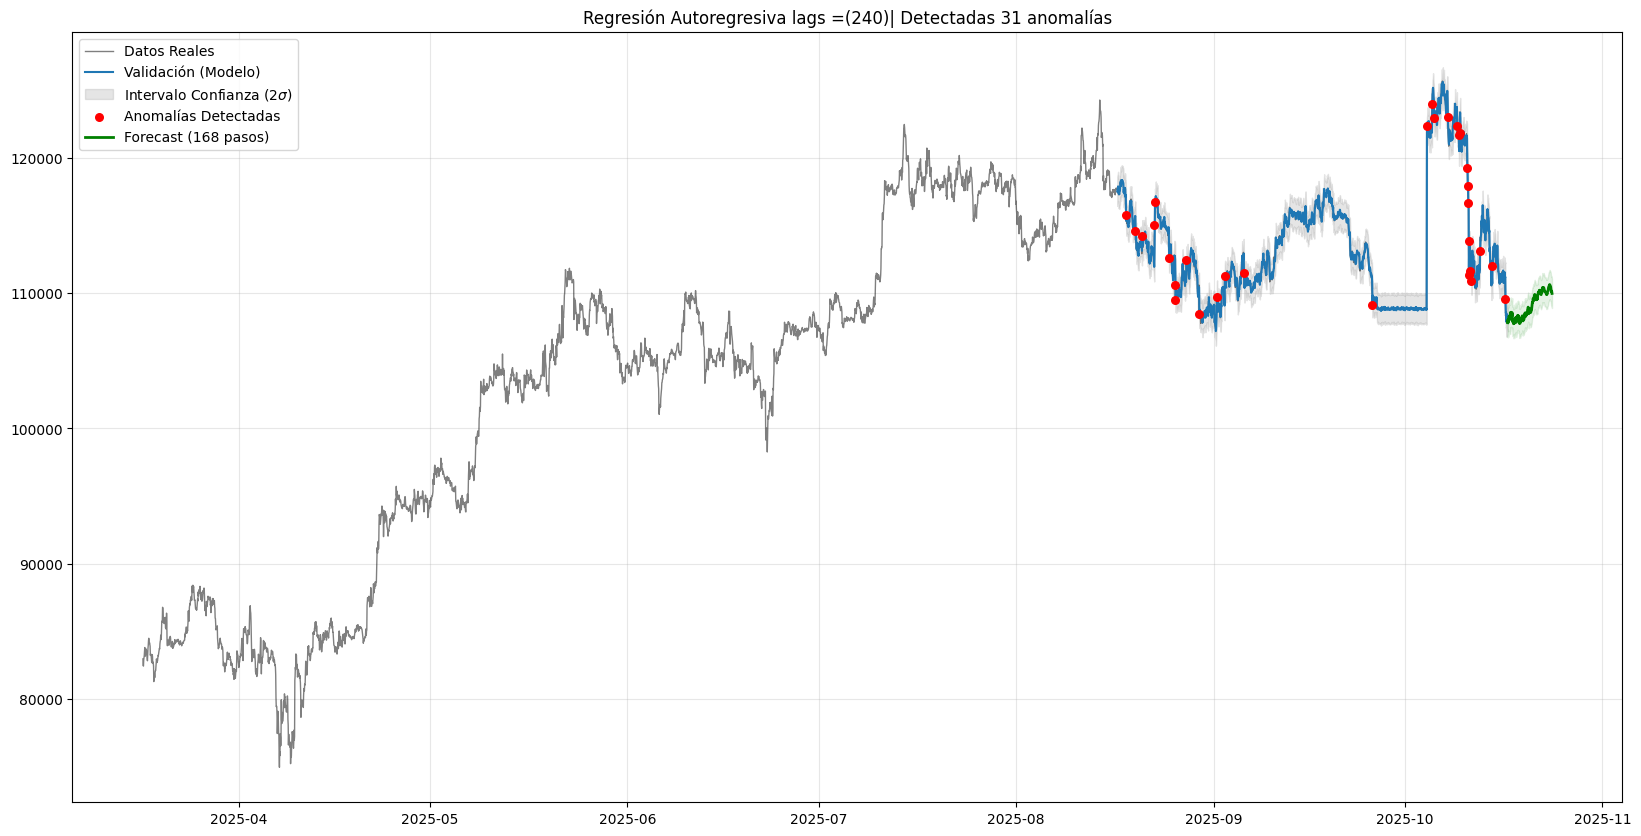

In [14]:
lags = [24,168,240]
for l in lags:
    
    mod =TimeSeriesLinearRegressor(lags =l)                      
    mod.fit(datos.price_usd)
    print(mod.score())
    mod.plot_all(steps = 168)